# Genetic-PC sensitivity and ancestry-stratified analyses (EUR + AFR)

This notebook contains two complementary genetic sensitivity analyses for the General Exposome-white matter association:

1. **Genetic population-structure adjustment:** compare the reference model with the same model additionally adjusted for ABCD genetic PC1-PC10, using the identical PC-complete participants within each split.
2. **Genetically stratified ancestry analyses:** refit the primary General Exposome-WM model within genetically defined European-ancestry (EUR) and African-ancestry (AFR) subsets. EUR membership is read from `Residual_ABCD_EUR_Mallard_Factor_1_PRS.csv`; AFR membership is read from `ext_scz_PGIs_resid_AFR.csv` using the `IID` column.
3. **Split-half ancestry analysis:** estimate EUR and AFR effects separately in discovery and replication and compare each ancestry-specific effect map with the corresponding full-sample map.
4. **Pooled ancestry analysis:** repeat EUR and AFR analyses in the full harmonized ABCD dataset (`dfFULL_macro_plus_NODDI_12_10.csv`) to increase subgroup sample size.
5. **EUR-AFR concordance:** directly compare EUR and AFR effect maps in discovery, replication, and the pooled/full harmonized analysis.

The ancestry-stratified models use the **same primary model specification** as the main analysis (`WM ~ General Exposome + age + sex + image quality`) and do **not** additionally adjust for genetic PCs. The PC-adjusted analysis is a separate sensitivity analysis.

**Caregiver-reported race/ethnicity adjustment is intentionally not included in this version.**

In [1]:
from pathlib import Path
import re
import gc
import importlib
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, linregress
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

import partial_r as pr
importlib.reload(pr)

<module 'partial_r' from '/mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/code/partial_r.py'>

In [2]:
ROOT_DIR = Path('/mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome')
RESULTS_DIR = ROOT_DIR / 'output_data' / 'results'
OUTPUT_DIR = RESULTS_DIR / 'reviewer_revision' / 'reviewer2_ancestry_pc'
FIG_DIR = ROOT_DIR / 'figures' / 'reviewer2_ancestry_pc'

EUR_FILE = ROOT_DIR / 'input_data' / 'Residual_ABCD_EUR_Mallard_Factor_1_PRS.csv'
AFR_FILE = ROOT_DIR / 'input_data' / 'ext_scz_PGIs_resid_AFR.csv'
FULL_DATA_FILE = RESULTS_DIR / 'dfFULL_macro_plus_NODDI_12_10.csv'

DATA_FILES = {
    'A_combined': RESULTS_DIR / 'dfA_macro_plus_NODDI_12_10.csv',
    'B_combined': RESULTS_DIR / 'dfB_macro_plus_NODDI_12_10.csv',
}

PHENO_DIR = Path('/mnt/isilon/bgdlab_hbcd/shared_data/ABCD/LASSO_tabular_tmp/abcd/rawdata/phenotype')
STATIC_FILE = PHENO_DIR / 'ab_g_stc.parquet'

N_PCS = 10
MASS_UNIVARIATE_QC = 't1post_dwi_contrast'
TARGET = 'General_SES'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print('OUTPUT_DIR:', OUTPUT_DIR)
print('STATIC_FILE:', STATIC_FILE, '| exists=', STATIC_FILE.exists())
print('EUR_FILE:', EUR_FILE, '| exists=', EUR_FILE.exists())
print('AFR_FILE:', AFR_FILE, '| exists=', AFR_FILE.exists())
print('FULL_DATA_FILE:', FULL_DATA_FILE, '| exists=', FULL_DATA_FILE.exists())
for name, path in DATA_FILES.items():
    print(f'{name}: {path} | exists={path.exists()}')

OUTPUT_DIR: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/reviewer2_ancestry_pc
STATIC_FILE: /mnt/isilon/bgdlab_hbcd/shared_data/ABCD/LASSO_tabular_tmp/abcd/rawdata/phenotype/ab_g_stc.parquet | exists= True
EUR_FILE: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/input_data/Residual_ABCD_EUR_Mallard_Factor_1_PRS.csv | exists= True
AFR_FILE: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/input_data/ext_scz_PGIs_resid_AFR.csv | exists= True
FULL_DATA_FILE: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfFULL_macro_plus_NODDI_12_10.csv | exists= True
A_combined: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfA_macro_plus_NODDI_12_10.csv | exists=True
B_combined: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfB_macro_plus_NODDI_12_10.csv | exists

## 1. Load ABCD genetic PC1-PC10

Only genetic population-structure PCs are loaded here. No caregiver-reported race/ethnicity variables enter this notebook.

In [3]:
static = pd.read_parquet(STATIC_FILE)
print('Static table shape:', static.shape)

if 'participant_id' not in static.columns:
    raise ValueError('Expected participant_id in ab_g_stc.parquet')

pc_candidates = sorted(
    [c for c in static.columns if c.startswith('ab_g_stc__gen_pc__')],
    key=lambda c: int(re.search(r'(\d+)$', c).group(1)),
)

if len(pc_candidates) < N_PCS:
    raise ValueError(f'Expected at least {N_PCS} genetic PCs; found {len(pc_candidates)}')

PC_COLS_RAW = pc_candidates[:N_PCS]
PC_COLS = [f'genPC{i}' for i in range(1, N_PCS + 1)]

print(f'Using PC1-PC{N_PCS}:')
print(PC_COLS_RAW)

Static table shape: (11860, 147)
Using PC1-PC10:
['ab_g_stc__gen_pc__01', 'ab_g_stc__gen_pc__02', 'ab_g_stc__gen_pc__03', 'ab_g_stc__gen_pc__04', 'ab_g_stc__gen_pc__05', 'ab_g_stc__gen_pc__06', 'ab_g_stc__gen_pc__07', 'ab_g_stc__gen_pc__08', 'ab_g_stc__gen_pc__09', 'ab_g_stc__gen_pc__10']


In [4]:
def clean_abcd_id(series):
    """Normalize common ABCD ID prefixes to match subject_id_clean."""
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r'^sub-', '', regex=True)
        .str.replace(r'^NDAR_', '', regex=True)
        .str.replace(r'^NDAR', '', regex=True)
        .str.replace(r'^INV', '', regex=True)
    )

person = static[['participant_id'] + PC_COLS_RAW].copy()
person['subject_id_clean'] = clean_abcd_id(person['participant_id'])
person[PC_COLS_RAW] = person[PC_COLS_RAW].apply(pd.to_numeric, errors='coerce')
person = person.rename(columns=dict(zip(PC_COLS_RAW, PC_COLS)))

dup_n = int(person['subject_id_clean'].duplicated().sum())
print('Duplicated cleaned participant IDs:', dup_n)
if dup_n:
    display(person.loc[
        person['subject_id_clean'].duplicated(keep=False),
        ['participant_id', 'subject_id_clean']
    ].head(10))
    raise ValueError('Duplicate cleaned participant IDs found in ab_g_stc; inspect before merging.')

print('\nPC missingness:')
display(person[PC_COLS].isna().sum().rename('n_missing').to_frame())

Duplicated cleaned participant IDs: 0

PC missingness:


,n_missing
genPC1,190
genPC2,190
genPC3,190
genPC4,190
genPC5,190
genPC6,190
genPC7,190
genPC8,190
genPC9,190
genPC10,190


## 2. Build the PC-complete split-half comparison sample

For the reference-vs-PC sensitivity analysis, each split is restricted only to participants with complete PC1-PC10. This ensures that the reference and PC-adjusted models use identical participants without additionally restricting on race/ethnicity availability.

In [5]:
def clean_bundle_columns_inplace(df):
    """Match Figure 2: drop *_mean bundle summaries and use median summaries."""
    mean_cols = [c for c in df.columns if c.startswith('bundle_') and c.endswith('_mean')]
    if mean_cols:
        df.drop(columns=mean_cols, inplace=True)

    rename_map = {
        c: c[:-len('_median')]
        for c in df.columns
        if c.startswith('bundle_') and c.endswith('_median')
    }
    if rename_map:
        df.rename(columns=rename_map, inplace=True)

analysis_dfs = {}
sample_rows = []
merge_cols = ['subject_id_clean'] + PC_COLS

for name, path in DATA_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f'Missing Figure 2 input: {path}')

    print(f'\nLoading {name}...')
    df = pd.read_csv(path)

    split = name[0]
    expected_group = 1 if split == 'A' else 2
    if 'matched_group' not in df.columns:
        raise ValueError(f'{name} is missing matched_group')

    df = df.loc[df['matched_group'] == expected_group].copy()
    n_split = len(df)

    clean_bundle_columns_inplace(df)
    df['subject_id_clean'] = clean_abcd_id(df['subject_id_clean'])

    df = df.merge(
        person[merge_cols],
        on='subject_id_clean',
        how='left',
        validate='many_to_one',
        indicator='_static_merge',
    )

    n_static_match = int((df['_static_merge'] == 'both').sum())
    df.drop(columns='_static_merge', inplace=True)

    complete_pc = df[PC_COLS].notna().all(axis=1)
    n_pc = int(complete_pc.sum())

    df = df.loc[complete_pc].reset_index(drop=True)
    analysis_dfs[split] = df

    sample_rows.append({
        'split': split,
        'n_after_matched_group': n_split,
        'n_static_match': n_static_match,
        'n_complete_PC1_PC10': n_pc,
    })

    print(
        f'{split}: {n_split} split participants -> {n_static_match} static-table matches -> '
        f'{n_pc} complete PC1-PC10'
    )

sample_sizes = pd.DataFrame(sample_rows).sort_values('split')
display(sample_sizes)
sample_sizes.to_csv(OUTPUT_DIR / 'common_sample_sizes_PC_only.csv', index=False)

features_A = [c for c in analysis_dfs['A'].columns if c.startswith('bundle_')]
features_B = [c for c in analysis_dfs['B'].columns if c.startswith('bundle_')]
if features_A != features_B:
    raise ValueError('A/B tables do not contain identical ordered bundle_ feature columns')
features = features_A

print('\nNumber of Figure-2-style WM features:', len(features))
if len(features) != 1302:
    print('WARNING: expected 1,302 WM features. Inspect before interpreting results.')

# Release large static tables before fitting all WM models.
del static, person
gc.collect()


Loading A_combined...
A: 4081 split participants -> 4079 static-table matches -> 4029 complete PC1-PC10

Loading B_combined...
B: 4099 split participants -> 4097 static-table matches -> 4057 complete PC1-PC10


,split,n_after_matched_group,n_static_match,n_complete_PC1_PC10
0,A,4081,4079,4029
1,B,4099,4097,4057



Number of Figure-2-style WM features: 1302


102

## 3. Reference vs genetic-PC-adjusted mass-univariate models

- **Reference:** `WM ~ General Exposome + age + sex + image quality`
- **Genetic-PC adjusted:** reference + `PC1 ... PC10`

The General Exposome remains the target predictor in both models, and both use exactly the same PC-complete participants within each split.

In [6]:
base_covars = ['age', 'sex', MASS_UNIVARIATE_QC, TARGET]
pc_covars = base_covars + PC_COLS

mu = {}

for split in ['A', 'B']:
    df = analysis_dfs[split]
    print(f'\n========== SPLIT {split} | N={len(df)} ==========')

    print('Running reference model...')
    mu[(split, 'base')] = pr.run_partial_r(
        df=df,
        msmt_cols=features,
        covariates=base_covars,
        target_cov=TARGET,
    )

    print('Running PC1-PC10-adjusted model...')
    mu[(split, 'pc')] = pr.run_partial_r(
        df=df,
        msmt_cols=features,
        covariates=pc_covars,
        target_cov=TARGET,
    )

    for label in ['base', 'pc']:
        mu[(split, label)].to_csv(
            OUTPUT_DIR / f'mass_univariate_{split}_{label}_PCcomplete_sample.csv',
            index=False,
        )


========== SPLIT A | N=4029 ==========
Running reference model...
Running PC1-PC10-adjusted model...

========== SPLIT B | N=4057 ==========
Running reference model...
Running PC1-PC10-adjusted model...


## 4. Quantify the effect of PC1-PC10 adjustment

We compare reference and PC-adjusted effect maps using map concordance, slope, mean absolute effect magnitude, attenuation, sign agreement, FDR counts, and split-half reproducibility.

In [7]:
def pearson_r(x, y):
    res = pearsonr(x, y)
    return float(res.statistic if hasattr(res, 'statistic') else res[0])

comparison_rows = []

for split in ['A', 'B']:
    n = len(analysis_dfs[split])

    base = mu[(split, 'base')][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_base', 'p_fdr': 'q_base'}
    )
    pc = mu[(split, 'pc')][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_pc', 'p_fdr': 'q_pc'}
    )
    m = base.merge(pc, on='feature', validate='one_to_one')

    x = m['r_base'].to_numpy(float)
    y = m['r_pc'].to_numpy(float)
    delta = y - x
    fit = linregress(x, y)
    mean_abs_base = float(np.mean(np.abs(x)))
    mean_abs_pc = float(np.mean(np.abs(y)))
    attenuation = 1 - (mean_abs_pc / mean_abs_base) if mean_abs_base > 0 else np.nan

    comparison_rows.append({
        'split': split,
        'n': n,
        'effect_concordance_vs_reference': pearson_r(x, y),
        'slope_vs_reference': float(fit.slope),
        'mean_abs_r_reference': mean_abs_base,
        'mean_abs_r_PC_adjusted': mean_abs_pc,
        'relative_reduction_mean_abs_r': float(attenuation),
        'mean_abs_delta_r': float(np.mean(np.abs(delta))),
        'max_abs_delta_r': float(np.max(np.abs(delta))),
        'sign_agreement': float(np.mean(np.sign(x) == np.sign(y))),
        'n_FDR_reference': int((m['q_base'] < .05).sum()),
        'n_FDR_PC_adjusted': int((m['q_pc'] < .05).sum()),
    })

    m.to_csv(
        OUTPUT_DIR / f'mass_univariate_{split}_reference_vs_pc.csv',
        index=False,
    )

pc_comparison_summary = pd.DataFrame(comparison_rows)
print('\nPC-adjusted vs reference:')
display(pc_comparison_summary.round(4))
pc_comparison_summary.to_csv(OUTPUT_DIR / 'PC_adjustment_summary.csv', index=False)


def split_half_r(model_label):
    A = mu[('A', model_label)][['feature', 'partial_r']].rename(columns={'partial_r': 'r_A'})
    B = mu[('B', model_label)][['feature', 'partial_r']].rename(columns={'partial_r': 'r_B'})
    ab = A.merge(B, on='feature', validate='one_to_one')
    return pearson_r(ab['r_A'], ab['r_B'])

split_summary = pd.DataFrame([
    {'model': 'reference', 'split_half_effect_concordance': split_half_r('base')},
    {'model': 'PC1-PC10 adjusted', 'split_half_effect_concordance': split_half_r('pc')},
])
print('\nSplit-half effect-map concordance:')
display(split_summary.round(4))
split_summary.to_csv(OUTPUT_DIR / 'split_half_concordance_reference_and_PC.csv', index=False)


PC-adjusted vs reference:


,split,n,effect_concordance_vs_reference,slope_vs_reference,mean_abs_r_reference,mean_abs_r_PC_adjusted,relative_reduction_mean_abs_r,mean_abs_delta_r,max_abs_delta_r,sign_agreement,n_FDR_reference,n_FDR_PC_adjusted
0,A,4029,0.8870,0.4724,0.0939,0.0484,0.4846,0.0509,0.1603,0.8794,1113,778
1,B,4057,0.8506,0.4553,0.0842,0.0409,0.5142,0.0526,0.1770,0.7995,1007,656



Split-half effect-map concordance:


,model,split_half_effect_concordance
0,reference,0.9427
1,PC1-PC10 adjusted,0.8186


### Optional descriptive check: General Exposome variance associated with PC1-PC10

In [8]:
def block_exposure_r2(df, split_label, block_cols):
    base_covs = ['age', 'sex', MASS_UNIVARIATE_QC]
    cols = [TARGET] + base_covs + list(block_cols)
    dat = df[cols].dropna().copy()

    y = dat[TARGET].astype(float)
    X_base = sm.add_constant(dat[base_covs].astype(float), has_constant='add')
    X_block = sm.add_constant(dat[base_covs + list(block_cols)].astype(float), has_constant='add')

    model_base = sm.OLS(y, X_base).fit()
    model_block = sm.OLS(y, X_block).fit()

    delta_r2 = model_block.rsquared - model_base.rsquared
    partial_r2 = delta_r2 / (1 - model_base.rsquared)

    return {
        'split': split_label,
        'block': 'PC1-PC10',
        'n': len(dat),
        'R2_age_sex_QC': model_base.rsquared,
        'R2_age_sex_QC_plus_PCs': model_block.rsquared,
        'delta_R2_PCs': delta_r2,
        'partial_R2_PCs': partial_r2,
    }

pc_exposure_summary = pd.DataFrame([
    block_exposure_r2(analysis_dfs[split], split, PC_COLS)
    for split in ['A', 'B']
])
print('Additional General Exposome variance associated with PC1-PC10:')
display(pc_exposure_summary.round(4))
pc_exposure_summary.to_csv(OUTPUT_DIR / 'GeneralExposome_variance_by_PC_block.csv', index=False)

Additional General Exposome variance associated with PC1-PC10:


,split,block,n,R2_age_sex_QC,R2_age_sex_QC_plus_PCs,delta_R2_PCs,partial_R2_PCs
0,A,PC1-PC10,4029,0.0147,0.4018,0.3871,0.3929
1,B,PC1-PC10,4057,0.0081,0.4094,0.4013,0.4046


## 5. Reference and PC-adjusted heatmaps

This is the two-column version of the sensitivity figure: reference model versus genetic PC1-PC10 adjusted model, separately for discovery and replication.

Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_ancestry_pc/SUPP_reference_vs_PC_mass_univariate_heatmaps.png


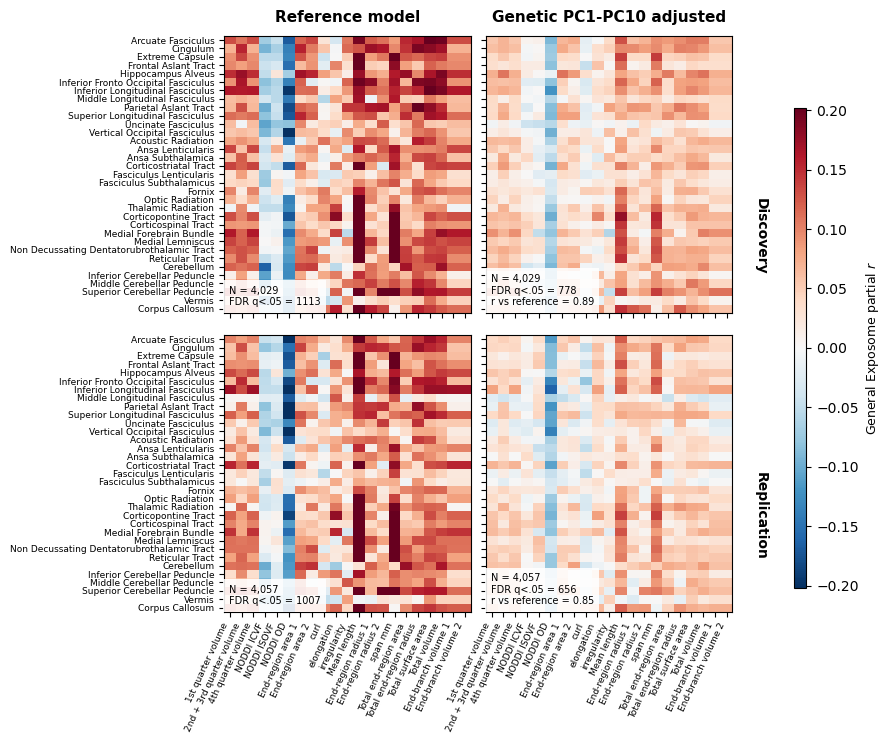

In [9]:
METRIC_ORDER = [
    '1st_quarter_volume_mm3',
    '2nd_and_3rd_quarter_volume_mm3',
    '4th_quarter_volume_mm3',
    'NODDI_icvf',
    'NODDI_isovf',
    'NODDI_od',
    'area_of_end_region_1_mm2',
    'area_of_end_region_2_mm2',
    'curl',
    'elongation',
    'irregularity',
    'mean_length_mm',
    'radius_of_end_region_1_mm',
    'radius_of_end_region_2_mm',
    'span_mm',
    'total_area_of_end_regions_mm2',
    'total_radius_of_end_regions_mm',
    'total_surface_area_mm2',
    'total_volume_mm3',
    'volume_of_end_branches_1',
    'volume_of_end_branches_2',
]

FAMILY_ORDER = {
    'Association': 0,
    'ProjectionBasalGanglia': 1,
    'ProjectionBrainstem': 2,
    'Cerebellum': 3,
    'Commissure': 4,
}

def pretty_metric(x):
    labels = {
        'NODDI_icvf': 'NODDI ICVF',
        'NODDI_isovf': 'NODDI ISOVF',
        'NODDI_od': 'NODDI OD',
        '1st_quarter_volume_mm3': '1st quarter volume',
        '2nd_and_3rd_quarter_volume_mm3': '2nd + 3rd quarter volume',
        '4th_quarter_volume_mm3': '4th quarter volume',
        'area_of_end_region_1_mm2': 'End-region area 1',
        'area_of_end_region_2_mm2': 'End-region area 2',
        'radius_of_end_region_1_mm': 'End-region radius 1',
        'radius_of_end_region_2_mm': 'End-region radius 2',
        'total_area_of_end_regions_mm2': 'Total end-region area',
        'total_radius_of_end_regions_mm': 'Total end-region radius',
        'total_surface_area_mm2': 'Total surface area',
        'total_volume_mm3': 'Total volume',
        'mean_length_mm': 'Mean length',
        'volume_of_end_branches_1': 'End-branch volume 1',
        'volume_of_end_branches_2': 'End-branch volume 2',
    }
    return labels.get(x, x.replace('_', ' '))

def camel_spaces(x):
    return re.sub(r'(?<!^)(?=[A-Z])', ' ', str(x)).strip()

def parse_results(df):
    rows = []
    for feature, r in zip(df['feature'], df['partial_r']):
        feature = str(feature)
        if feature.endswith('_median'):
            feature = feature[:-len('_median')]
        if not feature.startswith('bundle_'):
            continue

        parts = feature[len('bundle_'):].split('_')
        if len(parts) < 3:
            continue

        family, tract_hemi = parts[0], parts[1]
        metric = '_'.join(parts[2:])
        if metric not in METRIC_ORDER:
            continue

        tract = re.sub(r'(L|R)$', '', tract_hemi)
        rows.append((family, f'{family}::{tract}', camel_spaces(tract), metric, float(r)))

    out = pd.DataFrame(
        rows,
        columns=['family', 'tract_key', 'tract_label', 'metric', 'partial_r'],
    )
    return (
        out.groupby(['family', 'tract_key', 'tract_label', 'metric'], as_index=False)['partial_r']
        .mean()
    )

parsed = {
    (split, model): parse_results(mu[(split, model)])
    for split in ['A', 'B']
    for model in ['base', 'pc']
}

tract_info = pd.concat([
    parsed[('A', 'base')][['family', 'tract_key', 'tract_label']],
    parsed[('B', 'base')][['family', 'tract_key', 'tract_label']],
], ignore_index=True).drop_duplicates()
tract_info['family_order'] = tract_info['family'].map(FAMILY_ORDER).fillna(99)
tract_info = tract_info.sort_values(['family_order', 'tract_label']).reset_index(drop=True)
TRACT_ORDER = tract_info['tract_key'].tolist()
TRACT_LABELS = tract_info['tract_label'].tolist()

def make_matrix(df):
    return (
        df.pivot(index='tract_key', columns='metric', values='partial_r')
        .reindex(index=TRACT_ORDER, columns=METRIC_ORDER)
    )

mats = {
    (split, model): make_matrix(parsed[(split, model)])
    for split in ['A', 'B']
    for model in ['base', 'pc']
}

vals = np.concatenate([m.to_numpy().ravel() for m in mats.values()])
vals = vals[np.isfinite(vals)]
vmax = np.nanpercentile(np.abs(vals), 98)
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

n_by_split = dict(zip(sample_sizes['split'], sample_sizes['n_complete_PC1_PC10']))
panel_stats_pc = {}
for split in ['A', 'B']:
    base_r = mu[(split, 'base')][['feature', 'partial_r']].rename(columns={'partial_r': 'r_base'})
    for model in ['base', 'pc']:
        res = mu[(split, model)]
        s = {
            'n': int(n_by_split[split]),
            'n_fdr': int((res['p_fdr'] < .05).sum()),
        }
        if model == 'pc':
            adj = res[['feature', 'partial_r']].rename(columns={'partial_r': 'r_adj'})
            comp = base_r.merge(adj, on='feature', validate='one_to_one')
            s['map_r'] = pearson_r(comp['r_base'], comp['r_adj'])
        panel_stats_pc[(split, model)] = s

fig, axes = plt.subplots(2, 2, figsize=(8.2, 8), sharex=True, sharey=True)
for col, title in enumerate(['Reference model', 'Genetic PC1-PC10 adjusted']):
    axes[0, col].set_title(title, fontsize=11, fontweight='bold', pad=10)

for row, split in enumerate(['A', 'B']):
    for col, model in enumerate(['base', 'pc']):
        ax = axes[row, col]
        im = ax.imshow(
            mats[(split, model)].to_numpy(),
            aspect='auto',
            cmap='RdBu_r',
            norm=norm,
            interpolation='nearest',
        )
        s = panel_stats_pc[(split, model)]
        text = f"N = {s['n']:,}\nFDR q<.05 = {s['n_fdr']}"
        if model == 'pc':
            text += f"\nr vs reference = {s['map_r']:.2f}"
        ax.text(
            .02, .02, text,
            transform=ax.transAxes,
            fontsize=7,
            ha='left', va='bottom',
            bbox=dict(facecolor='white', edgecolor='none', alpha=.88),
        )

metric_labels = [pretty_metric(x) for x in METRIC_ORDER]
for ax in axes[-1, :]:
    ax.set_xticks(np.arange(len(METRIC_ORDER)))
    ax.set_xticklabels(metric_labels, rotation=65, ha='right', fontsize=6.5)

for row in range(2):
    axes[row, 0].set_yticks(np.arange(len(TRACT_ORDER)))
    axes[row, 0].set_yticklabels(TRACT_LABELS, fontsize=6.5)
for ax in axes[:, 1:].flat:
    ax.tick_params(axis='y', labelleft=False)

fig.text(.885, .66, 'Discovery', rotation=270, va='center', ha='center', fontsize=10, fontweight='bold')
fig.text(.885, .31, 'Replication', rotation=270, va='center', ha='center', fontsize=10, fontweight='bold')

cbar_ax = fig.add_axes([.925, .22, .015, .60])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r'General Exposome partial $r$', fontsize=9)

fig.subplots_adjust(left=.23, right=.85, bottom=.19, top=.91, wspace=.06, hspace=.08)
out_path = FIG_DIR / 'SUPP_reference_vs_PC_mass_univariate_heatmaps.png'
fig.savefig(out_path, dpi=250, bbox_inches='tight', pad_inches=.08)
print('Saved:', out_path)
plt.show()
plt.close(fig)

Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_ancestry_pc/GeneralExposome_reference_vs_PC_adjustment.png


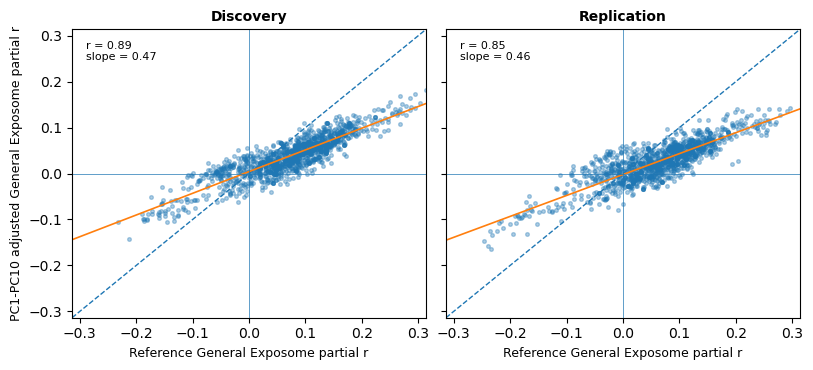

In [10]:
# Compact feature-wise concordance plot: reference vs PC-adjusted
all_plot_vals = [
    mu[(split, model)]['partial_r'].to_numpy(float)
    for split in ['A', 'B']
    for model in ['base', 'pc']
]
global_lim = max(np.max(np.abs(v)) for v in all_plot_vals)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.8), sharex=True, sharey=True)
for col, split in enumerate(['A', 'B']):
    base = mu[(split, 'base')][['feature', 'partial_r']].rename(columns={'partial_r': 'r_base'})
    pc = mu[(split, 'pc')][['feature', 'partial_r']].rename(columns={'partial_r': 'r_pc'})
    m = base.merge(pc, on='feature', validate='one_to_one')

    x = m['r_base'].to_numpy(float)
    y = m['r_pc'].to_numpy(float)
    r = pearson_r(x, y)
    fit = linregress(x, y)

    ax = axes[col]
    ax.scatter(x, y, s=7, alpha=.35, rasterized=True)
    ax.plot([-global_lim, global_lim], [-global_lim, global_lim], '--', linewidth=1)
    xx = np.linspace(-global_lim, global_lim, 100)
    ax.plot(xx, fit.intercept + fit.slope * xx, linewidth=1.2)
    ax.axhline(0, linewidth=.5)
    ax.axvline(0, linewidth=.5)
    ax.set_xlim(-global_lim, global_lim)
    ax.set_ylim(-global_lim, global_lim)
    ax.set_title('Discovery' if split == 'A' else 'Replication', fontsize=10, fontweight='bold')
    ax.set_xlabel('Reference General Exposome partial r', fontsize=9)
    ax.text(
        .04, .96,
        f'r = {r:.2f}\nslope = {fit.slope:.2f}',
        transform=ax.transAxes,
        ha='left', va='top', fontsize=8,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.8),
    )
axes[0].set_ylabel('PC1-PC10 adjusted General Exposome partial r', fontsize=9)
fig.tight_layout()
path = FIG_DIR / 'GeneralExposome_reference_vs_PC_adjustment.png'
fig.savefig(path, dpi=250, bbox_inches='tight')
print('Saved:', path)
plt.show()
plt.close(fig)

## 6. Genetically stratified ancestry analyses: EUR and AFR

Ancestry membership is determined only by participant-ID membership in the supplied EUR and AFR files. The stratified models use the unadjusted primary model rather than adding genetic PCs within subgroup.

In [11]:
def load_ancestry_ids(path, id_col, label):
    if not path.exists():
        raise FileNotFoundError(f'{label} ancestry file not found: {path}')

    ids_df = pd.read_csv(path, usecols=[id_col])
    ids_df['subject_id_clean'] = clean_abcd_id(ids_df[id_col])
    ids_df = ids_df.loc[
        ids_df['subject_id_clean'].notna()
        & ~ids_df['subject_id_clean'].isin(['', 'nan', 'None', '<NA>'])
    ].copy()

    id_set = set(ids_df['subject_id_clean'].unique())
    print(f'{label}: {len(ids_df):,} rows -> {len(id_set):,} unique cleaned participant IDs')
    return id_set


eur_ids = load_ancestry_ids(EUR_FILE, 'src_subject_id', 'EUR')
afr_ids = load_ancestry_ids(AFR_FILE, 'IID', 'AFR')

ancestry_id_sets = {'EUR': eur_ids, 'AFR': afr_ids}
overlap_ids = eur_ids.intersection(afr_ids)
print(f'EUR/AFR ID overlap: {len(overlap_ids):,}')
if overlap_ids:
    print('WARNING: EUR and AFR membership files contain overlapping cleaned IDs; inspect before interpretation.')

ANCESTRY_OUTPUT_DIR = OUTPUT_DIR / 'stratified_genetic_ancestry'
ANCESTRY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EUR: 5,815 rows -> 5,815 unique cleaned participant IDs
AFR: 1,402 rows -> 1,402 unique cleaned participant IDs
EUR/AFR ID overlap: 0


### 6a. Full primary split-half reference models

These use the full primary discovery and replication samples and are independent of PC missingness. They provide the appropriate full-sample reference maps for the ancestry-stratified comparisons.

In [12]:
general_mu = {}
primary_rows = []

for split, path, expected_group in [
    ('A', DATA_FILES['A_combined'], 1),
    ('B', DATA_FILES['B_combined'], 2),
]:
    print('\n' + '=' * 60)
    print(f'Full primary sample: split {split}')
    print('=' * 60)

    df = pd.read_csv(path)
    df = df.loc[df['matched_group'] == expected_group].copy()
    clean_bundle_columns_inplace(df)
    df['subject_id_clean'] = clean_abcd_id(df['subject_id_clean'])

    features_full = [c for c in df.columns if c.startswith('bundle_')]
    if len(features_full) != 1302:
        raise ValueError(f'Expected 1302 WM features; found {len(features_full)}')

    covars = ['age', 'sex', MASS_UNIVARIATE_QC, TARGET]
    n_complete = int(df[covars].notna().all(axis=1).sum())
    print(f'Split N: {len(df):,}; complete primary covariates: {n_complete:,}')

    res = pr.run_partial_r(
        df=df,
        msmt_cols=features_full,
        covariates=covars,
        target_cov=TARGET,
    )
    general_mu[split] = res.copy()

    primary_rows.append({
        'sample': 'Full',
        'split': split,
        'n': len(df),
        'n_complete_model_covariates': n_complete,
        'mean_abs_r': float(np.mean(np.abs(res['partial_r']))),
        'median_abs_r': float(np.median(np.abs(res['partial_r']))),
        'n_FDR': int((res['p_fdr'] < .05).sum()),
    })

    res.to_csv(
        ANCESTRY_OUTPUT_DIR / f'mass_univariate_{split}_FULL_reference.csv',
        index=False,
    )
    del df, res
    gc.collect()

primary_summary = pd.DataFrame(primary_rows)
print('\nFull primary split-half summary:')
display(primary_summary.round(4))


Full primary sample: split A
Split N: 4,081; complete primary covariates: 4,081

Full primary sample: split B
Split N: 4,099; complete primary covariates: 4,099

Full primary split-half summary:


,sample,split,n,n_complete_model_covariates,mean_abs_r,median_abs_r,n_FDR
0,Full,A,4081,4081,0.0942,0.0891,1119
1,Full,B,4099,4099,0.0840,0.0790,1009


### 6b. EUR and AFR models within discovery and replication

In [13]:
def run_split_ancestry_subset(label, id_set):
    out_mu = {}
    summary_rows = []
    match_rows = []

    for split, path, expected_group in [
        ('A', DATA_FILES['A_combined'], 1),
        ('B', DATA_FILES['B_combined'], 2),
    ]:
        print('\n' + '=' * 60)
        print(f'{label} ancestry: split {split}')
        print('=' * 60)

        df = pd.read_csv(path)
        df = df.loc[df['matched_group'] == expected_group].copy()
        n_primary = len(df)

        clean_bundle_columns_inplace(df)
        df['subject_id_clean'] = clean_abcd_id(df['subject_id_clean'])

        n_unique_imaging_ids = int(df['subject_id_clean'].nunique())
        matched_mask = df['subject_id_clean'].isin(id_set)
        sub = df.loc[matched_mask].copy().reset_index(drop=True)

        features_sub = [c for c in sub.columns if c.startswith('bundle_')]
        if len(features_sub) != 1302:
            raise ValueError(f'Expected 1302 WM features; found {len(features_sub)}')

        covars = ['age', 'sex', MASS_UNIVARIATE_QC, TARGET]
        n_complete = int(sub[covars].notna().all(axis=1).sum())

        match_rows.append({
            'ancestry': label,
            'split': split,
            'n_primary_imaging_rows': n_primary,
            'n_unique_imaging_ids': n_unique_imaging_ids,
            'n_ancestry_file_ids': len(id_set),
            'n_matched_imaging_rows': len(sub),
            'pct_primary_matched': 100 * len(sub) / n_primary if n_primary else np.nan,
            'n_complete_model_covariates': n_complete,
        })

        print(f'Primary split N: {n_primary:,}')
        print(f'{label} matched N: {len(sub):,} ({100*len(sub)/n_primary:.1f}%)')
        print(f'Complete primary-model covariates: {n_complete:,}')

        if len(sub) == 0:
            raise ValueError(f'No {label} ancestry participants matched in split {split}.')

        res = pr.run_partial_r(
            df=sub,
            msmt_cols=features_sub,
            covariates=covars,
            target_cov=TARGET,
        )
        out_mu[split] = res.copy()

        summary_rows.append({
            'ancestry': label,
            'split': split,
            'n': len(sub),
            'n_primary': n_primary,
            'mean_abs_r': float(np.mean(np.abs(res['partial_r']))),
            'median_abs_r': float(np.median(np.abs(res['partial_r']))),
            'n_FDR': int((res['p_fdr'] < .05).sum()),
        })

        res.to_csv(
            ANCESTRY_OUTPUT_DIR / f'mass_univariate_{split}_{label}_ancestry.csv',
            index=False,
        )

        del df, sub, res
        gc.collect()

    return out_mu, pd.DataFrame(summary_rows), pd.DataFrame(match_rows)


eur_mu, eur_summary, eur_match_qc = run_split_ancestry_subset('EUR', eur_ids)
afr_mu, afr_summary, afr_match_qc = run_split_ancestry_subset('AFR', afr_ids)

ancestry_split_summary = pd.concat([eur_summary, afr_summary], ignore_index=True)
ancestry_match_qc = pd.concat([eur_match_qc, afr_match_qc], ignore_index=True)

print('\nEUR/AFR split-half ancestry summary:')
display(ancestry_split_summary.round(4))
print('\nID-match QC:')
display(ancestry_match_qc.round(4))

ancestry_split_summary.to_csv(
    ANCESTRY_OUTPUT_DIR / 'EUR_AFR_split_half_ancestry_summary.csv',
    index=False,
)
ancestry_match_qc.to_csv(
    ANCESTRY_OUTPUT_DIR / 'EUR_AFR_split_half_ID_match_QC.csv',
    index=False,
)


EUR ancestry: split A
Primary split N: 4,081
EUR matched N: 2,151 (52.7%)
Complete primary-model covariates: 2,151

EUR ancestry: split B
Primary split N: 4,099
EUR matched N: 2,187 (53.4%)
Complete primary-model covariates: 2,187

AFR ancestry: split A
Primary split N: 4,081
AFR matched N: 399 (9.8%)
Complete primary-model covariates: 399

AFR ancestry: split B
Primary split N: 4,099
AFR matched N: 421 (10.3%)
Complete primary-model covariates: 421

EUR/AFR split-half ancestry summary:


,ancestry,split,n,n_primary,mean_abs_r,median_abs_r,n_FDR
0,EUR,A,2151,4081,0.0440,0.0354,453
1,EUR,B,2187,4099,0.0446,0.0354,453
2,AFR,A,399,4081,0.0619,0.0548,19
3,AFR,B,421,4099,0.0523,0.0459,0



ID-match QC:


,ancestry,split,n_primary_imaging_rows,n_unique_imaging_ids,n_ancestry_file_ids,n_matched_imaging_rows,pct_primary_matched,n_complete_model_covariates
0,EUR,A,4081,4081,5815,2151,52.7077,2151
1,EUR,B,4099,4099,5815,2187,53.3545,2187
2,AFR,A,4081,4081,1402,399,9.7770,399
3,AFR,B,4099,4099,1402,421,10.2708,421


### 6c. Split-half subgroup comparisons and direct EUR-AFR concordance

For each ancestry subgroup we compare its effect map with the corresponding full-sample map. We also directly compare EUR and AFR effect maps within each split. These EUR-AFR comparisons are descriptive because the groups differ substantially in sample size.

In [14]:
ancestry_mu = {'EUR': eur_mu, 'AFR': afr_mu}
ancestry_summaries = {'EUR': eur_summary, 'AFR': afr_summary}

subgroup_comparison_rows = []
split_repro_rows = []

for label in ['EUR', 'AFR']:
    subgroup_mu = ancestry_mu[label]

    for split in ['A', 'B']:
        full = general_mu[split][['feature', 'partial_r', 'p_fdr']].rename(
            columns={'partial_r': 'r_full', 'p_fdr': 'q_full'}
        )
        subgroup = subgroup_mu[split][['feature', 'partial_r', 'p_fdr']].rename(
            columns={'partial_r': 'r_subgroup', 'p_fdr': 'q_subgroup'}
        )
        comp = full.merge(subgroup, on='feature', validate='one_to_one')

        n_subgroup = int(
            ancestry_summaries[label]
            .loc[ancestry_summaries[label]['split'] == split, 'n']
            .iloc[0]
        )
        n_full = int(primary_summary.loc[primary_summary['split'] == split, 'n'].iloc[0])

        subgroup_comparison_rows.append({
            'ancestry': label,
            'split': split,
            'n_full': n_full,
            'n_subgroup': n_subgroup,
            'full_vs_subgroup_map_r': pearson_r(comp['r_full'], comp['r_subgroup']),
            'slope_subgroup_vs_full': float(linregress(comp['r_full'], comp['r_subgroup']).slope),
            'sign_agreement': float(np.mean(np.sign(comp['r_full']) == np.sign(comp['r_subgroup']))),
            'mean_abs_r_full': float(np.mean(np.abs(comp['r_full']))),
            'mean_abs_r_subgroup': float(np.mean(np.abs(comp['r_subgroup']))),
            'mean_abs_delta_r': float(np.mean(np.abs(comp['r_subgroup'] - comp['r_full']))),
            'n_FDR_full': int((comp['q_full'] < .05).sum()),
            'n_FDR_subgroup': int((comp['q_subgroup'] < .05).sum()),
        })

        comp.to_csv(
            ANCESTRY_OUTPUT_DIR / f'{split}_FULL_vs_{label}_feature_comparison.csv',
            index=False,
        )

    A = subgroup_mu['A'][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_A', 'p_fdr': 'q_A'}
    )
    B = subgroup_mu['B'][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_B', 'p_fdr': 'q_B'}
    )
    ab = A.merge(B, on='feature', validate='one_to_one')

    split_repro_rows.append({
        'ancestry': label,
        'discovery_replication_map_r': pearson_r(ab['r_A'], ab['r_B']),
        'sign_agreement': float(np.mean(np.sign(ab['r_A']) == np.sign(ab['r_B']))),
        'n_FDR_discovery': int((ab['q_A'] < .05).sum()),
        'n_FDR_replication': int((ab['q_B'] < .05).sum()),
        'n_FDR_both_splits': int(((ab['q_A'] < .05) & (ab['q_B'] < .05)).sum()),
    })

    ab.to_csv(
        ANCESTRY_OUTPUT_DIR / f'{label}_split_half_feature_comparison.csv',
        index=False,
    )

subgroup_comparison_summary = pd.DataFrame(subgroup_comparison_rows)
split_repro_summary = pd.DataFrame(split_repro_rows)

print('\nFull sample vs ancestry subgroup, by split:')
display(subgroup_comparison_summary.round(4))
print('\nWithin-ancestry discovery-replication reproducibility:')
display(split_repro_summary.round(4))

subgroup_comparison_summary.to_csv(
    ANCESTRY_OUTPUT_DIR / 'FULL_vs_EUR_AFR_split_summary.csv',
    index=False,
)
split_repro_summary.to_csv(
    ANCESTRY_OUTPUT_DIR / 'EUR_AFR_split_half_reproducibility.csv',
    index=False,
)

# Direct EUR-vs-AFR map comparisons within each split.
eur_afr_split_rows = []
eur_afr_split_tables = {}
for split in ['A', 'B']:
    eur = eur_mu[split][['feature', 'partial_r']].rename(columns={'partial_r': 'r_EUR'})
    afr = afr_mu[split][['feature', 'partial_r']].rename(columns={'partial_r': 'r_AFR'})
    comp = eur.merge(afr, on='feature', validate='one_to_one')
    eur_afr_split_tables[split] = comp

    fit = linregress(comp['r_EUR'], comp['r_AFR'])
    eur_afr_split_rows.append({
        'split': split,
        'EUR_vs_AFR_map_r': pearson_r(comp['r_EUR'], comp['r_AFR']),
        'slope_AFR_vs_EUR': float(fit.slope),
        'sign_agreement': float(np.mean(np.sign(comp['r_EUR']) == np.sign(comp['r_AFR']))),
        'mean_abs_EUR_minus_AFR_r': float(np.mean(np.abs(comp['r_EUR'] - comp['r_AFR']))),
    })
    comp.to_csv(
        ANCESTRY_OUTPUT_DIR / f'{split}_EUR_vs_AFR_feature_comparison.csv',
        index=False,
    )

eur_afr_split_summary = pd.DataFrame(eur_afr_split_rows)
print('\nDirect EUR-vs-AFR effect-map comparison within split:')
display(eur_afr_split_summary.round(4))
eur_afr_split_summary.to_csv(
    ANCESTRY_OUTPUT_DIR / 'EUR_vs_AFR_split_comparison.csv',
    index=False,
)


Full sample vs ancestry subgroup, by split:


,ancestry,split,n_full,n_subgroup,full_vs_subgroup_map_r,slope_subgroup_vs_full,sign_agreement,mean_abs_r_full,mean_abs_r_subgroup,mean_abs_delta_r,n_FDR_full,n_FDR_subgroup
0,EUR,A,4081,2151,0.8162,0.4789,0.8149,0.0942,0.0440,0.0599,1119,453
1,EUR,B,4099,2187,0.7997,0.5209,0.7450,0.0840,0.0446,0.0553,1009,453
2,AFR,A,4081,399,0.3871,0.2778,0.7343,0.0942,0.0619,0.0705,1119,19
3,AFR,B,4099,421,0.5296,0.3819,0.7373,0.0840,0.0523,0.0634,1009,0



Within-ancestry discovery-replication reproducibility:


,ancestry,discovery_replication_map_r,sign_agreement,n_FDR_discovery,n_FDR_replication,n_FDR_both_splits
0,EUR,0.7857,0.7604,453,453,307
1,AFR,0.4540,0.7197,19,0,0



Direct EUR-vs-AFR effect-map comparison within split:


,split,EUR_vs_AFR_map_r,slope_AFR_vs_EUR,sign_agreement,mean_abs_EUR_minus_AFR_r
0,A,0.3235,0.3958,0.6813,0.0549
1,B,0.5024,0.5561,0.7143,0.0448


### 6d. Split-half heatmap: full sample vs EUR vs AFR

Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/reviewer2_ancestry_pc/stratified_genetic_ancestry/Split_half_FULL_EUR_AFR_mass_univariate_heatmap.png


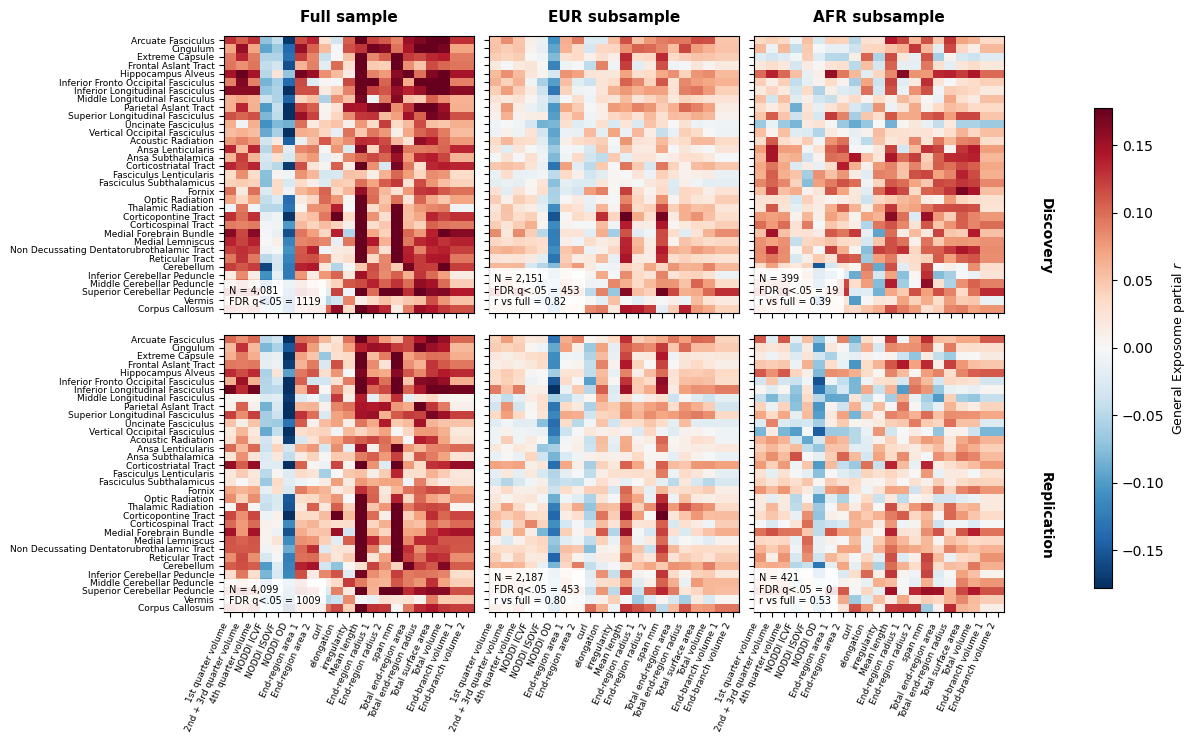

In [15]:
# ------------------------------------------------------------------
# 8e. Split-half heatmap: Full vs EUR vs AFR
# ------------------------------------------------------------------
# Reuses METRIC_ORDER, FAMILY_ORDER, parse_results, TRACT_ORDER,
# TRACT_LABELS, and make_matrix defined in the preceding figure section.

required_objects = [
    "general_mu", "eur_mu", "afr_mu", "primary_summary",
    "eur_summary", "afr_summary", "parse_results", "make_matrix",
]
missing_objects = [x for x in required_objects if x not in globals()]
if missing_objects:
    raise RuntimeError(f"Missing required objects: {missing_objects}")

split_parsed = {}
for split in ["A", "B"]:
    split_parsed[(split, "full")] = parse_results(general_mu[split])
    split_parsed[(split, "eur")] = parse_results(eur_mu[split])
    split_parsed[(split, "afr")] = parse_results(afr_mu[split])

split_mats = {
    key: make_matrix(df)
    for key, df in split_parsed.items()
}

vals = np.concatenate([m.to_numpy().ravel() for m in split_mats.values()])
vals = vals[np.isfinite(vals)]
vmax = np.nanpercentile(np.abs(vals), 98)
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

full_n = dict(zip(primary_summary["split"], primary_summary["n"]))
eur_n = dict(zip(eur_summary["split"], eur_summary["n"]))
afr_n = dict(zip(afr_summary["split"], afr_summary["n"]))

panel_stats = {}
for split in ["A", "B"]:
    full = general_mu[split]
    panel_stats[(split, "full")] = {
        "n": int(full_n[split]),
        "n_fdr": int((full["p_fdr"] < .05).sum()),
    }

    for label, key, subgroup_mu, n_lookup in [
        ("EUR", "eur", eur_mu, eur_n),
        ("AFR", "afr", afr_mu, afr_n),
    ]:
        subgroup = subgroup_mu[split]
        comp = (
            full[["feature", "partial_r"]]
            .rename(columns={"partial_r": "r_full"})
            .merge(
                subgroup[["feature", "partial_r"]]
                .rename(columns={"partial_r": "r_subgroup"}),
                on="feature",
                validate="one_to_one",
            )
        )
        panel_stats[(split, key)] = {
            "n": int(n_lookup[split]),
            "n_fdr": int((subgroup["p_fdr"] < .05).sum()),
            "map_r": pearson_r(comp["r_full"], comp["r_subgroup"]),
        }

fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)

for col, title in enumerate(["Full sample", "EUR subsample", "AFR subsample"]):
    axes[0, col].set_title(title, fontsize=11, fontweight="bold", pad=10)

for row, split in enumerate(["A", "B"]):
    for col, model in enumerate(["full", "eur", "afr"]):
        ax = axes[row, col]
        im = ax.imshow(
            split_mats[(split, model)].to_numpy(),
            aspect="auto",
            cmap="RdBu_r",
            norm=norm,
            interpolation="nearest",
        )

        s = panel_stats[(split, model)]
        text = f"N = {s['n']:,}\nFDR q<.05 = {s['n_fdr']}"
        if model != "full":
            text += f"\nr vs full = {s['map_r']:.2f}"

        ax.text(
            .02, .02, text,
            transform=ax.transAxes,
            fontsize=7,
            ha="left", va="bottom",
            bbox=dict(facecolor="white", edgecolor="none", alpha=.88),
        )

metric_labels = [pretty_metric(x) for x in METRIC_ORDER]
for ax in axes[-1, :]:
    ax.set_xticks(np.arange(len(METRIC_ORDER)))
    ax.set_xticklabels(metric_labels, rotation=65, ha="right", fontsize=6.5)

for row in range(2):
    axes[row, 0].set_yticks(np.arange(len(TRACT_ORDER)))
    axes[row, 0].set_yticklabels(TRACT_LABELS, fontsize=6.5)

for ax in axes[:, 1:].flat:
    ax.tick_params(axis="y", labelleft=False)

fig.text(.885, .66, "Discovery", rotation=270, va="center", ha="center", fontsize=10, fontweight="bold")
fig.text(.885, .31, "Replication", rotation=270, va="center", ha="center", fontsize=10, fontweight="bold")

cbar_ax = fig.add_axes([.925, .22, .015, .60])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r"General Exposome partial $r$", fontsize=9)

fig.subplots_adjust(left=.20, right=.85, bottom=.19, top=.91, wspace=.06, hspace=.08)

split_heatmap_path = ANCESTRY_OUTPUT_DIR / "Split_half_FULL_EUR_AFR_mass_univariate_heatmap.png"
fig.savefig(split_heatmap_path, dpi=250, bbox_inches="tight", pad_inches=.08)
print("Saved:", split_heatmap_path)
plt.show()
plt.close(fig)

## 7. Pooled EUR and AFR analyses using the full harmonized ABCD dataset

These analyses use the full harmonized imaging table to maximize ancestry-subgroup sample size. EUR and AFR are each compared with the full pooled reference map and directly with one another.

In [16]:
# ------------------------------------------------------------------
# 9a. Load the full harmonized imaging dataset and perform ID-match QC
# ------------------------------------------------------------------

FULL_ANCESTRY_DIR = ANCESTRY_OUTPUT_DIR / "full_harmonized"
FULL_ANCESTRY_DIR.mkdir(parents=True, exist_ok=True)

if not FULL_DATA_FILE.exists():
    raise FileNotFoundError(f"Full harmonized imaging file not found: {FULL_DATA_FILE}")

full_df = pd.read_csv(FULL_DATA_FILE)
clean_bundle_columns_inplace(full_df)

if "subject_id_clean" not in full_df.columns:
    raise ValueError("Expected subject_id_clean in the full harmonized imaging table")

full_df["subject_id_clean"] = clean_abcd_id(full_df["subject_id_clean"])

features_full_pooled = [c for c in full_df.columns if c.startswith("bundle_")]
if len(features_full_pooled) != 1302:
    raise ValueError(f"Expected 1302 WM features in full dataset; found {len(features_full_pooled)}")

n_duplicate_ids = int(full_df["subject_id_clean"].duplicated().sum())
print(f"Full harmonized rows: {len(full_df):,}")
print(f"Unique participant IDs: {full_df['subject_id_clean'].nunique():,}")
print(f"Duplicated cleaned participant IDs: {n_duplicate_ids:,}")
if n_duplicate_ids:
    print("WARNING: duplicated participant IDs detected in full harmonized table; inspect before interpretation.")

full_match_rows = []
for label, id_set in ancestry_id_sets.items():
    matched = full_df["subject_id_clean"].isin(id_set)
    full_match_rows.append({
        "ancestry": label,
        "n_full_imaging_rows": len(full_df),
        "n_unique_full_imaging_ids": int(full_df["subject_id_clean"].nunique()),
        "n_ancestry_file_ids": len(id_set),
        "n_matched_imaging_rows": int(matched.sum()),
        "pct_full_imaging_matched": 100 * float(matched.mean()),
    })

full_match_qc = pd.DataFrame(full_match_rows)
print("\nFull-dataset ancestry ID matching:")
display(full_match_qc.round(4))
full_match_qc.to_csv(
    FULL_ANCESTRY_DIR / "FULL_EUR_AFR_ID_match_QC.csv",
    index=False,
)

Full harmonized rows: 8,180
Unique participant IDs: 8,180
Duplicated cleaned participant IDs: 0

Full-dataset ancestry ID matching:


,ancestry,n_full_imaging_rows,n_unique_full_imaging_ids,n_ancestry_file_ids,n_matched_imaging_rows,pct_full_imaging_matched
0,EUR,8180,8180,5815,4338,53.0318
1,AFR,8180,8180,1402,820,10.0244


In [17]:
# ------------------------------------------------------------------
# 9b. Fit pooled full-sample, EUR, and AFR mass-univariate models
# ------------------------------------------------------------------

pooled_covars = ["age", "sex", MASS_UNIVARIATE_QC, TARGET]
pooled_mu = {}
pooled_summary_rows = []

pooled_samples = {
    "FULL": full_df,
    "EUR": full_df.loc[full_df["subject_id_clean"].isin(eur_ids)].copy(),
    "AFR": full_df.loc[full_df["subject_id_clean"].isin(afr_ids)].copy(),
}

for label, df in pooled_samples.items():
    print("\n" + "=" * 60)
    print(f"Pooled harmonized analysis: {label}")
    print("=" * 60)

    n_complete = int(df[pooled_covars].notna().all(axis=1).sum())
    print(f"N = {len(df):,}; complete primary-model covariates = {n_complete:,}")

    if len(df) == 0:
        raise ValueError(f"No participants available for pooled {label} analysis")

    res = pr.run_partial_r(
        df=df,
        msmt_cols=features_full_pooled,
        covariates=pooled_covars,
        target_cov=TARGET,
    )
    pooled_mu[label] = res.copy()

    pooled_summary_rows.append({
        "sample": label,
        "n": len(df),
        "n_complete_model_covariates": n_complete,
        "mean_abs_r": float(np.mean(np.abs(res["partial_r"]))),
        "median_abs_r": float(np.median(np.abs(res["partial_r"]))),
        "n_FDR": int((res["p_fdr"] < .05).sum()),
    })

    res.to_csv(
        FULL_ANCESTRY_DIR / f"mass_univariate_FULL_{label}.csv",
        index=False,
    )

pooled_summary = pd.DataFrame(pooled_summary_rows)
print("\nPooled ancestry summary:")
display(pooled_summary.round(4))
pooled_summary.to_csv(
    FULL_ANCESTRY_DIR / "FULL_EUR_AFR_ancestry_summary.csv",
    index=False,
)


Pooled harmonized analysis: FULL
N = 8,180; complete primary-model covariates = 8,180

Pooled harmonized analysis: EUR
N = 4,338; complete primary-model covariates = 4,338

Pooled harmonized analysis: AFR
N = 820; complete primary-model covariates = 820

Pooled ancestry summary:


,sample,n,n_complete_model_covariates,mean_abs_r,median_abs_r,n_FDR
0,FULL,8180,8180,0.0889,0.0839,1147
1,EUR,4338,4338,0.0418,0.0328,625
2,AFR,820,820,0.0513,0.0449,181


In [18]:
# ------------------------------------------------------------------
# 9c. Pooled subgroup-vs-full and EUR-vs-AFR comparisons
# ------------------------------------------------------------------

pooled_comparison_rows = []
full_res = (
    pooled_mu["FULL"][["feature", "partial_r", "p_fdr"]]
    .rename(columns={"partial_r": "r_full", "p_fdr": "q_full"})
)

for label in ["EUR", "AFR"]:
    sub = (
        pooled_mu[label][["feature", "partial_r", "p_fdr"]]
        .rename(columns={"partial_r": "r_subgroup", "p_fdr": "q_subgroup"})
    )
    comp = full_res.merge(sub, on="feature", validate="one_to_one")

    n_sub = int(pooled_summary.loc[pooled_summary["sample"] == label, "n"].iloc[0])
    n_full = int(pooled_summary.loc[pooled_summary["sample"] == "FULL", "n"].iloc[0])

    pooled_comparison_rows.append({
        "ancestry": label,
        "n_full": n_full,
        "n_subgroup": n_sub,
        "full_vs_subgroup_map_r": pearson_r(comp["r_full"], comp["r_subgroup"]),
        "slope_subgroup_vs_full": float(linregress(comp["r_full"], comp["r_subgroup"]).slope),
        "sign_agreement": float(np.mean(np.sign(comp["r_full"]) == np.sign(comp["r_subgroup"]))),
        "mean_abs_r_full": float(np.mean(np.abs(comp["r_full"]))),
        "mean_abs_r_subgroup": float(np.mean(np.abs(comp["r_subgroup"]))),
        "mean_abs_delta_r": float(np.mean(np.abs(comp["r_subgroup"] - comp["r_full"]))),
        "n_FDR_full": int((comp["q_full"] < .05).sum()),
        "n_FDR_subgroup": int((comp["q_subgroup"] < .05).sum()),
    })

    comp.to_csv(
        FULL_ANCESTRY_DIR / f"FULL_reference_vs_{label}_feature_comparison.csv",
        index=False,
    )

pooled_comparison_summary = pd.DataFrame(pooled_comparison_rows)
print("\nPooled full sample vs ancestry subgroups:")
display(pooled_comparison_summary.round(4))
pooled_comparison_summary.to_csv(
    FULL_ANCESTRY_DIR / "FULL_reference_vs_EUR_AFR_summary.csv",
    index=False,
)

# Direct pooled EUR-vs-AFR map comparison (descriptive).
eur = pooled_mu["EUR"][["feature", "partial_r"]].rename(columns={"partial_r": "r_EUR"})
afr = pooled_mu["AFR"][["feature", "partial_r"]].rename(columns={"partial_r": "r_AFR"})
eur_afr = eur.merge(afr, on="feature", validate="one_to_one")

pooled_eur_afr_summary = pd.DataFrame([{
    "EUR_vs_AFR_map_r": pearson_r(eur_afr["r_EUR"], eur_afr["r_AFR"]),
    "slope_AFR_vs_EUR": float(linregress(eur_afr["r_EUR"], eur_afr["r_AFR"]).slope),
    "sign_agreement": float(np.mean(np.sign(eur_afr["r_EUR"]) == np.sign(eur_afr["r_AFR"]))),
    "mean_abs_EUR_minus_AFR_r": float(np.mean(np.abs(eur_afr["r_EUR"] - eur_afr["r_AFR"]))),
}])

print("\nPooled EUR-vs-AFR effect-map comparison:")
display(pooled_eur_afr_summary.round(4))
pooled_eur_afr_summary.to_csv(
    FULL_ANCESTRY_DIR / "FULL_EUR_vs_AFR_comparison.csv",
    index=False,
)
eur_afr.to_csv(
    FULL_ANCESTRY_DIR / "FULL_EUR_vs_AFR_feature_comparison.csv",
    index=False,
)


Pooled full sample vs ancestry subgroups:


,ancestry,n_full,n_subgroup,full_vs_subgroup_map_r,slope_subgroup_vs_full,sign_agreement,mean_abs_r_full,mean_abs_r_subgroup,mean_abs_delta_r,n_FDR_full,n_FDR_subgroup
0,EUR,8180,4338,0.8280,0.4921,0.7842,0.0889,0.0418,0.0570,1147,625
1,AFR,8180,820,0.5329,0.3343,0.7788,0.0889,0.0513,0.0618,1147,181



Pooled EUR-vs-AFR effect-map comparison:


,EUR_vs_AFR_map_r,slope_AFR_vs_EUR,sign_agreement,mean_abs_EUR_minus_AFR_r
0,0.5176,0.5463,0.7243,0.0411


Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/reviewer2_ancestry_pc/stratified_genetic_ancestry/full_harmonized/FULL_harmonized_FULL_EUR_AFR_mass_univariate_heatmap.png


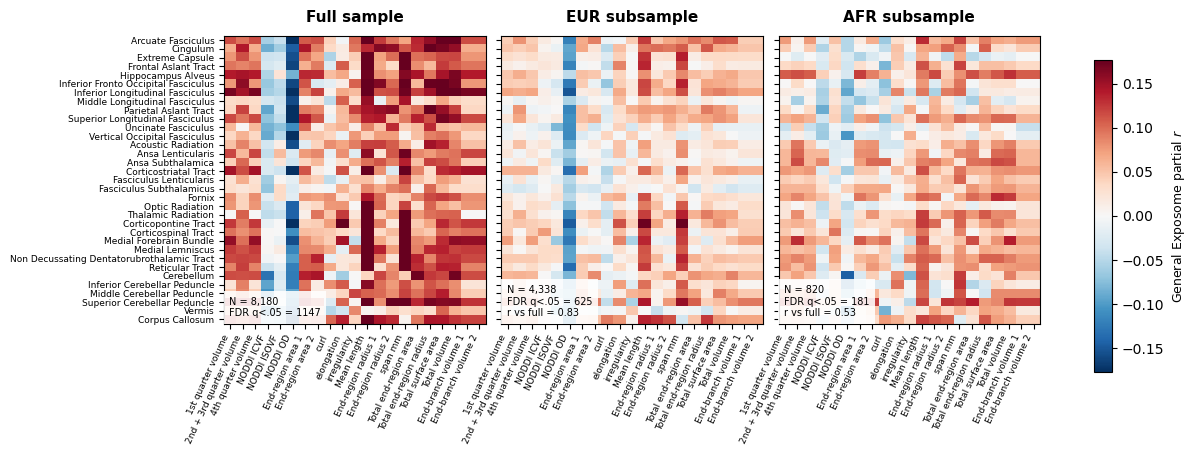

In [19]:
# ------------------------------------------------------------------
# 9d. Pooled heatmap: Full vs EUR vs AFR
# ------------------------------------------------------------------

pooled_parsed = {
    "full": parse_results(pooled_mu["FULL"]),
    "eur": parse_results(pooled_mu["EUR"]),
    "afr": parse_results(pooled_mu["AFR"]),
}
pooled_mats = {key: make_matrix(df) for key, df in pooled_parsed.items()}

vals = np.concatenate([m.to_numpy().ravel() for m in pooled_mats.values()])
vals = vals[np.isfinite(vals)]
vmax = np.nanpercentile(np.abs(vals), 98)
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

n_lookup = dict(zip(pooled_summary["sample"], pooled_summary["n"]))
panel_stats = {
    "full": {
        "n": int(n_lookup["FULL"]),
        "n_fdr": int((pooled_mu["FULL"]["p_fdr"] < .05).sum()),
    }
}

for label, key in [("EUR", "eur"), ("AFR", "afr")]:
    comp = (
        pooled_mu["FULL"][["feature", "partial_r"]]
        .rename(columns={"partial_r": "r_full"})
        .merge(
            pooled_mu[label][["feature", "partial_r"]]
            .rename(columns={"partial_r": "r_subgroup"}),
            on="feature",
            validate="one_to_one",
        )
    )
    panel_stats[key] = {
        "n": int(n_lookup[label]),
        "n_fdr": int((pooled_mu[label]["p_fdr"] < .05).sum()),
        "map_r": pearson_r(comp["r_full"], comp["r_subgroup"]),
    }

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), sharex=True, sharey=True)
for col, (model, title) in enumerate([
    ("full", "Full sample"),
    ("eur", "EUR subsample"),
    ("afr", "AFR subsample"),
]):
    ax = axes[col]
    im = ax.imshow(
        pooled_mats[model].to_numpy(),
        aspect="auto",
        cmap="RdBu_r",
        norm=norm,
        interpolation="nearest",
    )
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)

    s = panel_stats[model]
    text = f"N = {s['n']:,}\nFDR q<.05 = {s['n_fdr']}"
    if model != "full":
        text += f"\nr vs full = {s['map_r']:.2f}"
    ax.text(
        .02, .02, text,
        transform=ax.transAxes,
        fontsize=7,
        ha="left", va="bottom",
        bbox=dict(facecolor="white", edgecolor="none", alpha=.88),
    )

metric_labels = [pretty_metric(x) for x in METRIC_ORDER]
for ax in axes:
    ax.set_xticks(np.arange(len(METRIC_ORDER)))
    ax.set_xticklabels(metric_labels, rotation=65, ha="right", fontsize=6.5)

axes[0].set_yticks(np.arange(len(TRACT_ORDER)))
axes[0].set_yticklabels(TRACT_LABELS, fontsize=6.5)
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)

cbar_ax = fig.add_axes([.925, .20, .015, .65])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r"General Exposome partial $r$", fontsize=9)

fig.subplots_adjust(left=.20, right=.88, bottom=.30, top=.90, wspace=.06)

pooled_heatmap_path = FULL_ANCESTRY_DIR / "FULL_harmonized_FULL_EUR_AFR_mass_univariate_heatmap.png"
fig.savefig(pooled_heatmap_path, dpi=250, bbox_inches="tight", pad_inches=.08)
print("Saved:", pooled_heatmap_path)
plt.show()
plt.close(fig)

### 7e. Direct EUR-AFR effect-map association: discovery, replication, and pooled sample

This figure makes the EUR-AFR concordance explicit rather than reporting only summary statistics. Each point is one WM feature; the dashed line is identity and the solid line is the fitted relationship.

Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_ancestry_pc/EUR_vs_AFR_effect_map_concordance_split_and_pooled.png


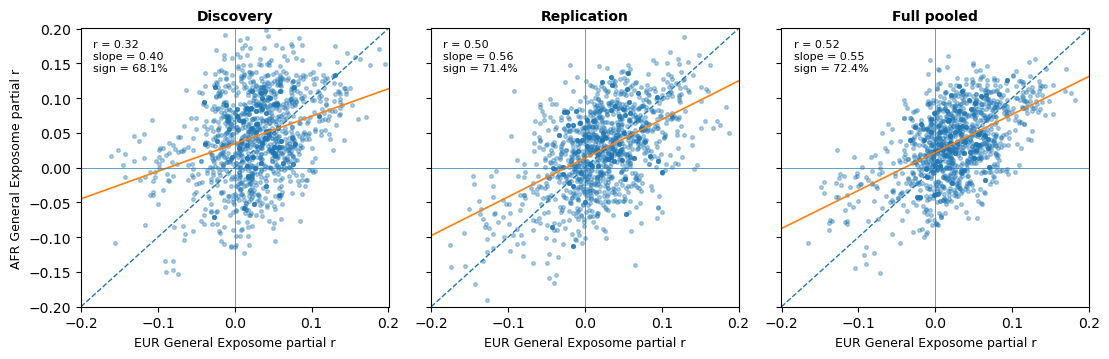


EUR-vs-AFR concordance across analyses:


,analysis,EUR_vs_AFR_map_r,slope_AFR_vs_EUR,sign_agreement,mean_abs_EUR_minus_AFR_r
0,Discovery,0.3235,0.3958,0.6813,0.0549
1,Replication,0.5024,0.5561,0.7143,0.0448
2,Full pooled,0.5176,0.5463,0.7243,0.0411


In [20]:
# Build a three-panel direct EUR-vs-AFR concordance figure.
comparison_sets = [
    ('Discovery', eur_afr_split_tables['A']),
    ('Replication', eur_afr_split_tables['B']),
    ('Full pooled', eur_afr),
]

all_vals = []
for _, comp in comparison_sets:
    all_vals.extend([comp['r_EUR'].to_numpy(float), comp['r_AFR'].to_numpy(float)])
lim = max(np.max(np.abs(v)) for v in all_vals)

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.7), sharex=True, sharey=True)
summary_rows = []

for ax, (title, comp) in zip(axes, comparison_sets):
    x = comp['r_EUR'].to_numpy(float)
    y = comp['r_AFR'].to_numpy(float)
    r = pearson_r(x, y)
    fit = linregress(x, y)
    sign_agreement = float(np.mean(np.sign(x) == np.sign(y)))
    mean_abs_delta = float(np.mean(np.abs(x - y)))

    summary_rows.append({
        'analysis': title,
        'EUR_vs_AFR_map_r': r,
        'slope_AFR_vs_EUR': float(fit.slope),
        'sign_agreement': sign_agreement,
        'mean_abs_EUR_minus_AFR_r': mean_abs_delta,
    })

    ax.scatter(x, y, s=7, alpha=.35, rasterized=True)
    ax.plot([-lim, lim], [-lim, lim], '--', linewidth=1)
    xx = np.linspace(-lim, lim, 100)
    ax.plot(xx, fit.intercept + fit.slope * xx, linewidth=1.2)
    ax.axhline(0, linewidth=.5)
    ax.axvline(0, linewidth=.5)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('EUR General Exposome partial r', fontsize=9)
    ax.text(
        .04, .96,
        f'r = {r:.2f}\nslope = {fit.slope:.2f}\nsign = {100*sign_agreement:.1f}%',
        transform=ax.transAxes,
        ha='left', va='top', fontsize=8,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.82),
    )

axes[0].set_ylabel('AFR General Exposome partial r', fontsize=9)
fig.tight_layout()

eur_afr_plot_path = FIG_DIR / 'EUR_vs_AFR_effect_map_concordance_split_and_pooled.png'
fig.savefig(eur_afr_plot_path, dpi=250, bbox_inches='tight', pad_inches=.08)
print('Saved:', eur_afr_plot_path)
plt.show()
plt.close(fig)

combined_eur_afr_summary = pd.DataFrame(summary_rows)
print('\nEUR-vs-AFR concordance across analyses:')
display(combined_eur_afr_summary.round(4))
combined_eur_afr_summary.to_csv(
    ANCESTRY_OUTPUT_DIR / 'EUR_vs_AFR_concordance_split_and_pooled.csv',
    index=False,
)

## 8. Compact source-of-truth ancestry summary

In [21]:
# ------------------------------------------------------------------
# 9e. Compact source-of-truth ancestry summary
# ------------------------------------------------------------------

# Split-half rows: one row per ancestry x split.
split_comp_for_merge = subgroup_comparison_summary.copy()
split_out = ancestry_split_summary.merge(
    split_comp_for_merge,
    on=["ancestry", "split"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_comparison"),
)
split_out.insert(0, "analysis", "split_half")

# Add discovery-replication reproducibility to both split rows for each ancestry.
split_out = split_out.merge(
    split_repro_summary,
    on="ancestry",
    how="left",
    validate="many_to_one",
)

# Pooled rows: one per ancestry.
pooled_subgroups = pooled_summary.loc[pooled_summary["sample"].isin(["EUR", "AFR"])].copy()
pooled_subgroups = pooled_subgroups.rename(columns={"sample": "ancestry"})
pooled_out = pooled_subgroups.merge(
    pooled_comparison_summary,
    on="ancestry",
    how="left",
    validate="one_to_one",
    suffixes=("", "_comparison"),
)
pooled_out.insert(0, "analysis", "full_harmonized")
pooled_out.insert(2, "split", "FULL")

# Keep union of columns; blank fields are expected where a statistic does not apply.
ancestry_source_of_truth = pd.concat([split_out, pooled_out], ignore_index=True, sort=False)

source_path = ANCESTRY_OUTPUT_DIR / "EUR_AFR_ANCESTRY_SOURCE_OF_TRUTH.csv"
ancestry_source_of_truth.to_csv(source_path, index=False)
print("Saved:", source_path)
display(ancestry_source_of_truth.round(4))

Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/reviewer2_ancestry_pc/stratified_genetic_ancestry/EUR_AFR_ANCESTRY_SOURCE_OF_TRUTH.csv


,analysis,ancestry,split,n,n_primary,mean_abs_r,median_abs_r,n_FDR,n_full,n_subgroup,...,mean_abs_delta_r,n_FDR_full,n_FDR_subgroup,discovery_replication_map_r,sign_agreement_y,n_FDR_discovery,n_FDR_replication,n_FDR_both_splits,n_complete_model_covariates,sign_agreement
0,split_half,EUR,A,2151,4081.0,0.0440,0.0354,453,4081,2151,...,0.0599,1119,453,0.7857,0.7604,453.0,453.0,307.0,NaN,NaN
1,split_half,EUR,B,2187,4099.0,0.0446,0.0354,453,4099,2187,...,0.0553,1009,453,0.7857,0.7604,453.0,453.0,307.0,NaN,NaN
2,split_half,AFR,A,399,4081.0,0.0619,0.0548,19,4081,399,...,0.0705,1119,19,0.4540,0.7197,19.0,0.0,0.0,NaN,NaN
3,split_half,AFR,B,421,4099.0,0.0523,0.0459,0,4099,421,...,0.0634,1009,0,0.4540,0.7197,19.0,0.0,0.0,NaN,NaN
4,full_harmonized,EUR,FULL,4338,NaN,0.0418,0.0328,625,8180,4338,...,0.0570,1147,625,NaN,NaN,NaN,NaN,NaN,4338.0,0.7842
5,full_harmonized,AFR,FULL,820,NaN,0.0513,0.0449,181,8180,820,...,0.0618,1147,181,NaN,NaN,NaN,NaN,NaN,820.0,0.7788
